In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

from utils.complex_param import complex_param, de_phase_solution
from utils.fourth_order_runge_kuta import rk_interval
from utils.model import cosine_kernel_fft, kuramoto_kernel, vf_r_theta
from utils.plotting_utils import generate_yticks_and_labels
from utils.self_consistency import self_consistency_root

BASE_FOLDER = Path("./paper_plots")
BASE_FOLDER.mkdir(parents=True, exist_ok=True)

In [11]:
N = 1024
A = 0.995
alpha = (np.pi / 2) - 0.16
kernel_fft = cosine_kernel_fft(A, N)

omegas = np.zeros(N)

np.random.seed(seed=1338)


dt = 0.1
evolve_time = 500.0
t_evolve_eval = np.arange(0, evolve_time+dt, dt)
t_evolve_span =  (0, evolve_time+dt)


initial_conditions = (
    6.0
    * np.exp(-0.76 * (np.linspace(-np.pi, np.pi, N, endpoint=False)) ** 2)
    * (np.random.random(N) - 0.5)
)

In [12]:
kuramoto = kuramoto_kernel(omegas, kernel_fft, alpha=alpha)
sol = solve_ivp(
    lambda t, y: kuramoto(y),
    t_evolve_span,
    initial_conditions,
    t_eval=t_evolve_eval,
    method="RK45",
    rtol=1e-7,
    atol=1e-10,
)
init_state = sol.y.T

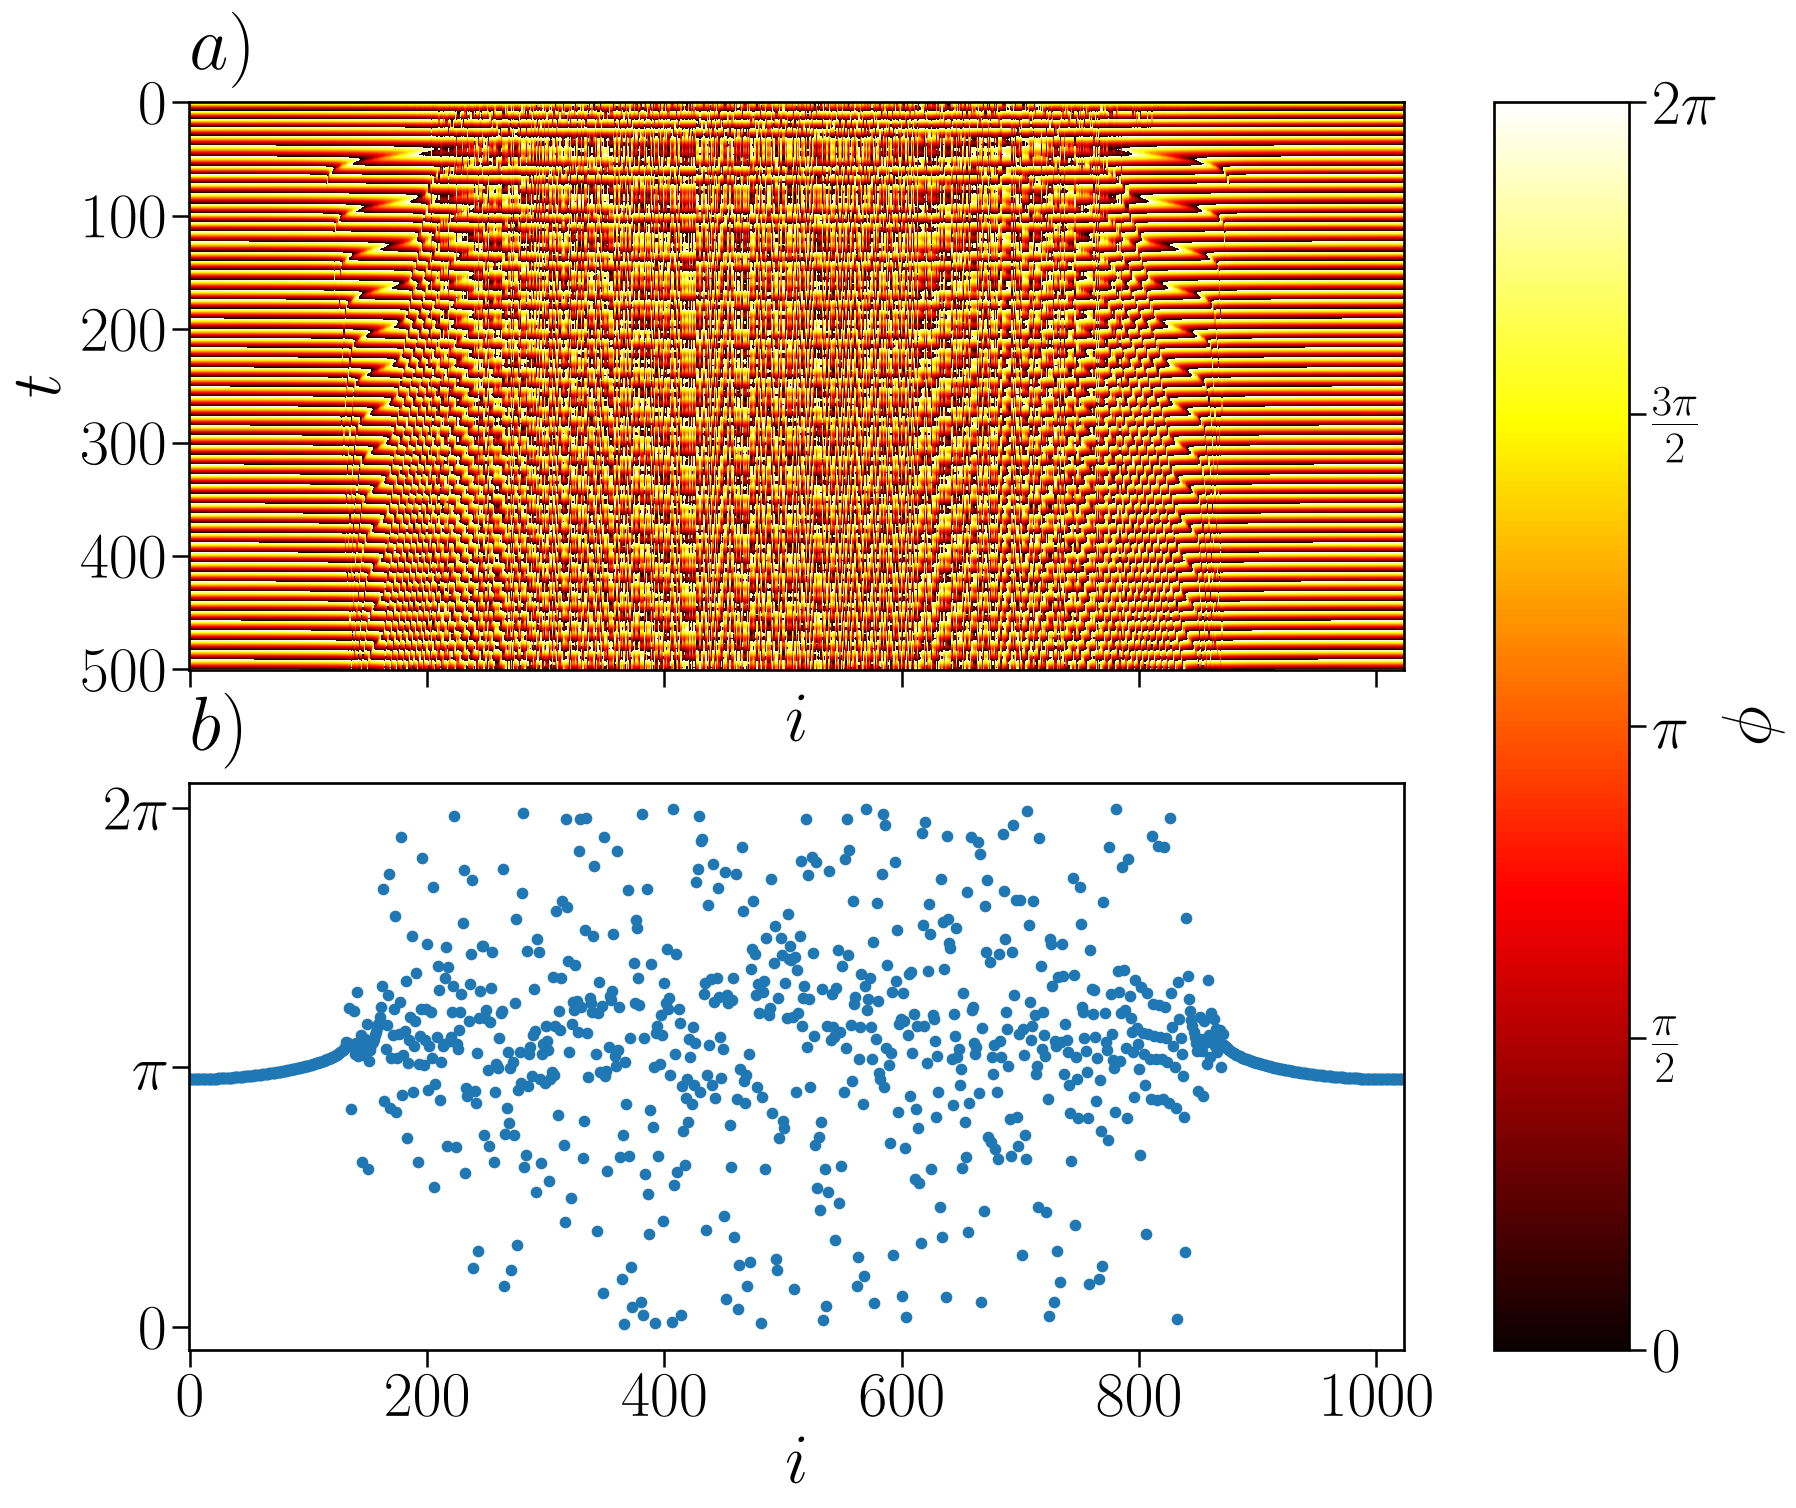

In [13]:
yticks, ytick_labels = generate_yticks_and_labels(sol, evolve_time)

fig, ax = plt.subplots(2, sharex=True)
heatmap = ax[0].imshow(
    init_state % (2 * np.pi), aspect="auto", interpolation="none", cmap="hot"
)

ax[0].set_yticks(yticks)
ax[0].set_yticklabels(ytick_labels)
ax[0].set_ylabel(r"$t$")
ax[0].set_xlabel(r"$i$")
ax[0].set_title(r"$a)$", loc="left")


# Scatter plot
ax[1].scatter(np.arange(N), (init_state[5000] % (2 * np.pi) - np.pi) % (2* np.pi))
ax[1].set_xlabel(r"$i$")
ax[1].set_yticks([0, np.pi, 2 * np.pi])
ax[1].set_yticklabels([r"$0$", r"$\pi$", r"$2\pi$"])
ax[1].set_title(r"$b)$", loc="left")


cax = plt.axes((0.85, 0.1, 0.075, 0.8))
cbar = fig.colorbar(heatmap, cax=cax)
cbar.set_label(r"$\phi$")
cbar.set_ticks([0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi])
cbar.set_ticklabels(
    [r"$0$", r"$\frac{\pi}{2}$", r"$\pi$", r"$\frac{3\pi}{2}$", r"$2\pi$"]
)

plt.subplots_adjust(bottom=0.1, right=0.8, top=0.9)

plt.show()

In [14]:
t_span = (0, evolve_time)
sol = solve_ivp(
    lambda t, y: kuramoto(y),
    t_evolve_span,
    init_state[-1],
    t_eval=t_evolve_eval,
    method="RK45",
    rtol=1e-7,
    atol=1e-10,
)
init_state = sol.y.T

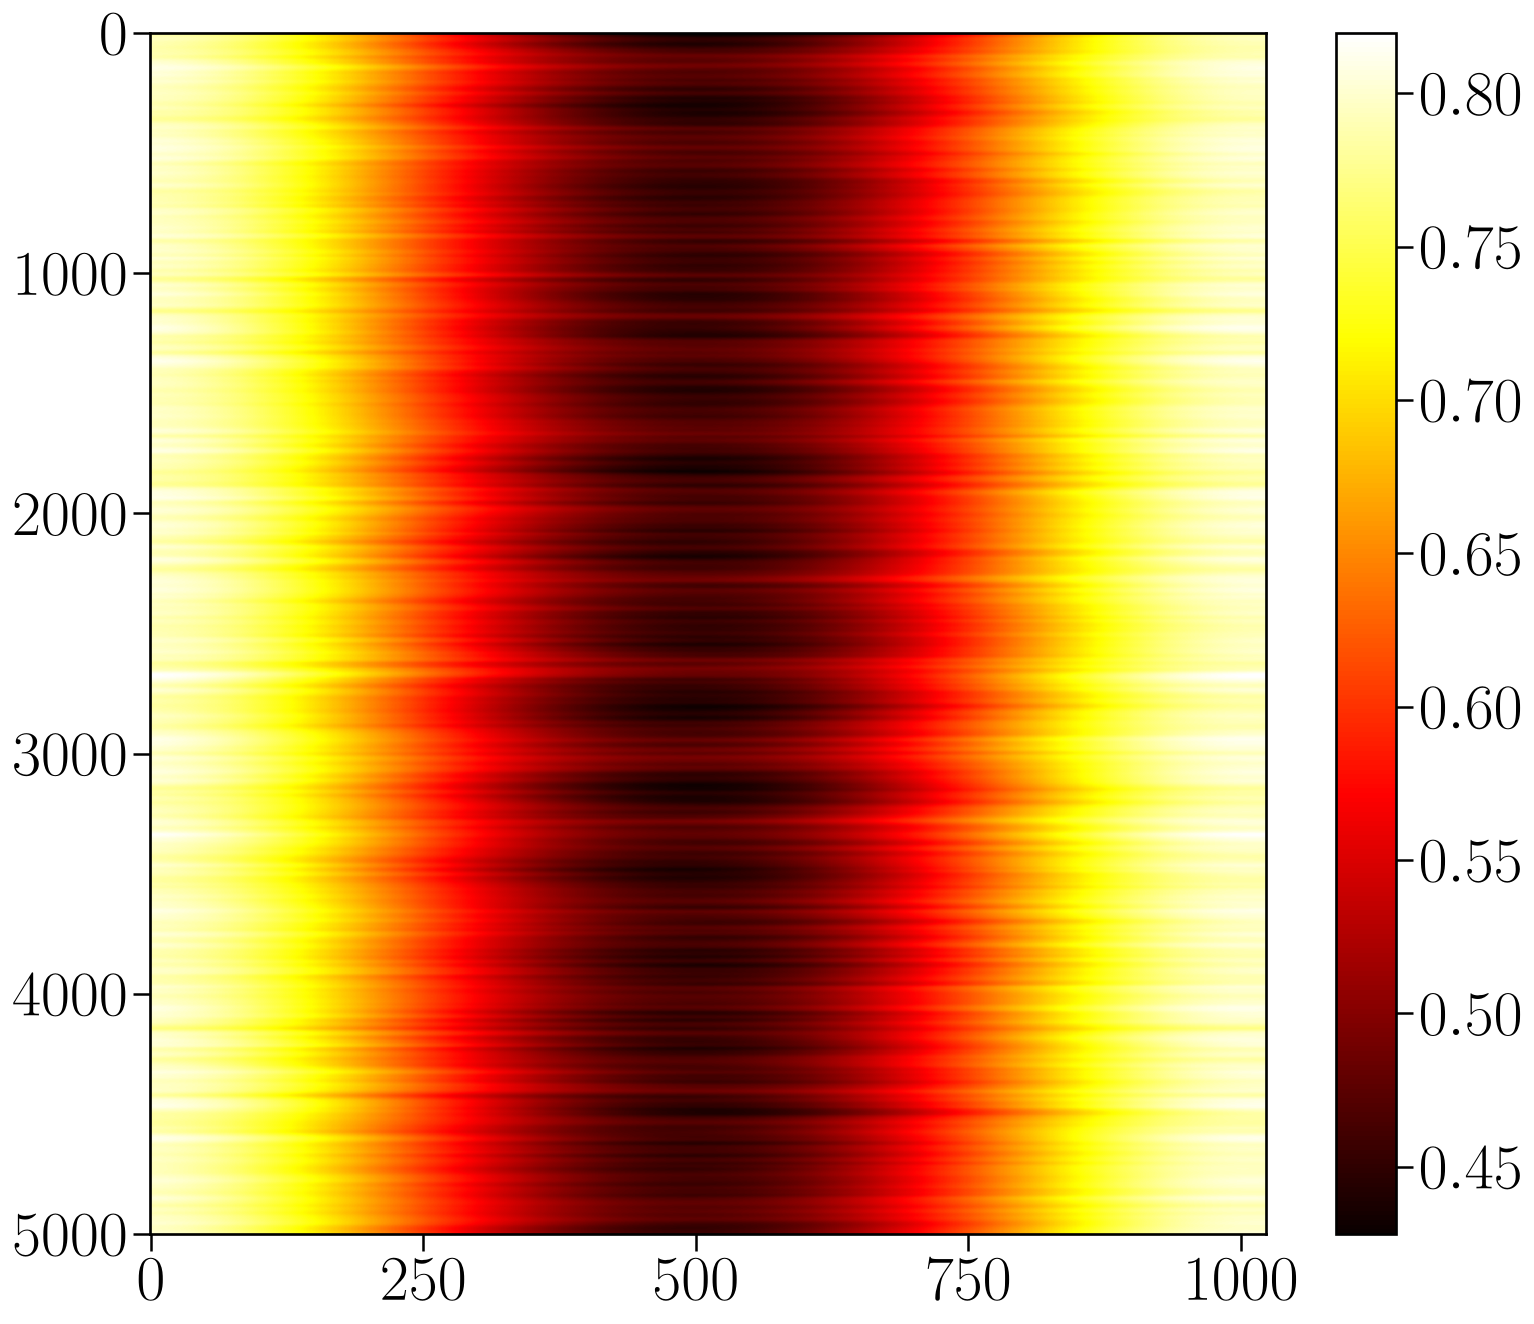

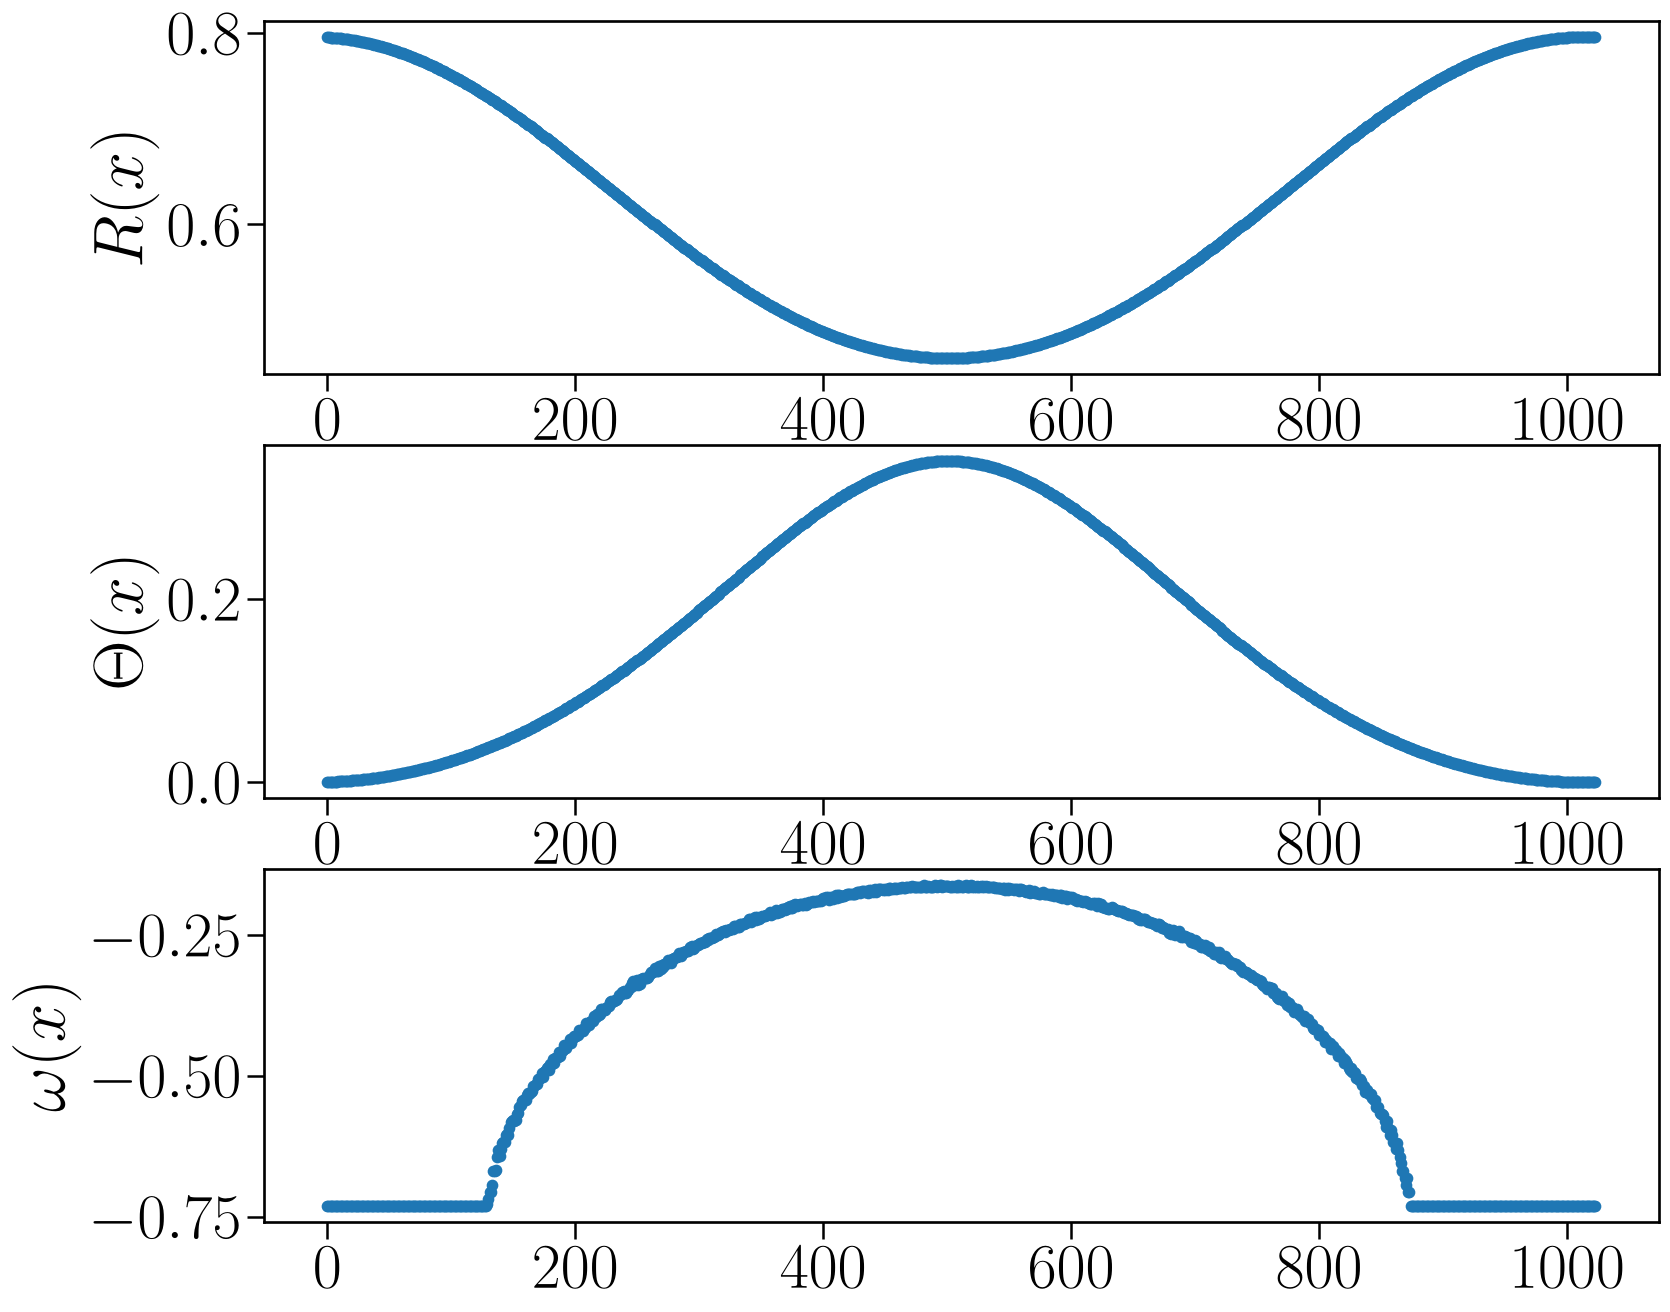

In [15]:
z = complex_param(init_state, kernel_fft)
plt.figure()
heatmap = plt.imshow(np.abs(z), aspect="auto", interpolation="none", cmap="hot")
plt.colorbar(heatmap)
plt.show()

r_orig = np.mean(np.abs(z), axis=0)
theta_orig = np.unwrap(np.unwrap(np.angle(z), axis=0).mean(axis=0))
theta_orig = theta_orig - np.min(theta_orig)

unwrap_state = np.unwrap(init_state, axis=0)
omega_real = (np.diff(unwrap_state, axis=0)).mean(axis=0) / 0.1

fig, ax = plt.subplots(3)
ax[0].scatter(np.arange(N), r_orig)
ax[0].set_ylabel(r"$R(x)$")

ax[1].scatter(np.arange(N), theta_orig)
ax[1].set_ylabel(r"$\Theta(x)$")

ax[2].scatter(np.arange(N), omega_real)
ax[2].set_ylabel(r"$\omega(x)$")
plt.show()

In [16]:
r_sol, theta_sol, Omega, root_result = self_consistency_root(
    r_orig,
    theta_orig,
    np.min(omega_real),
    kernel_fft,
    omegas,
    alpha,
    options={}
)
print(root_result.success, root_result.message)
Omega

True A solution was found at the specified tolerance.


-0.7313408546276666

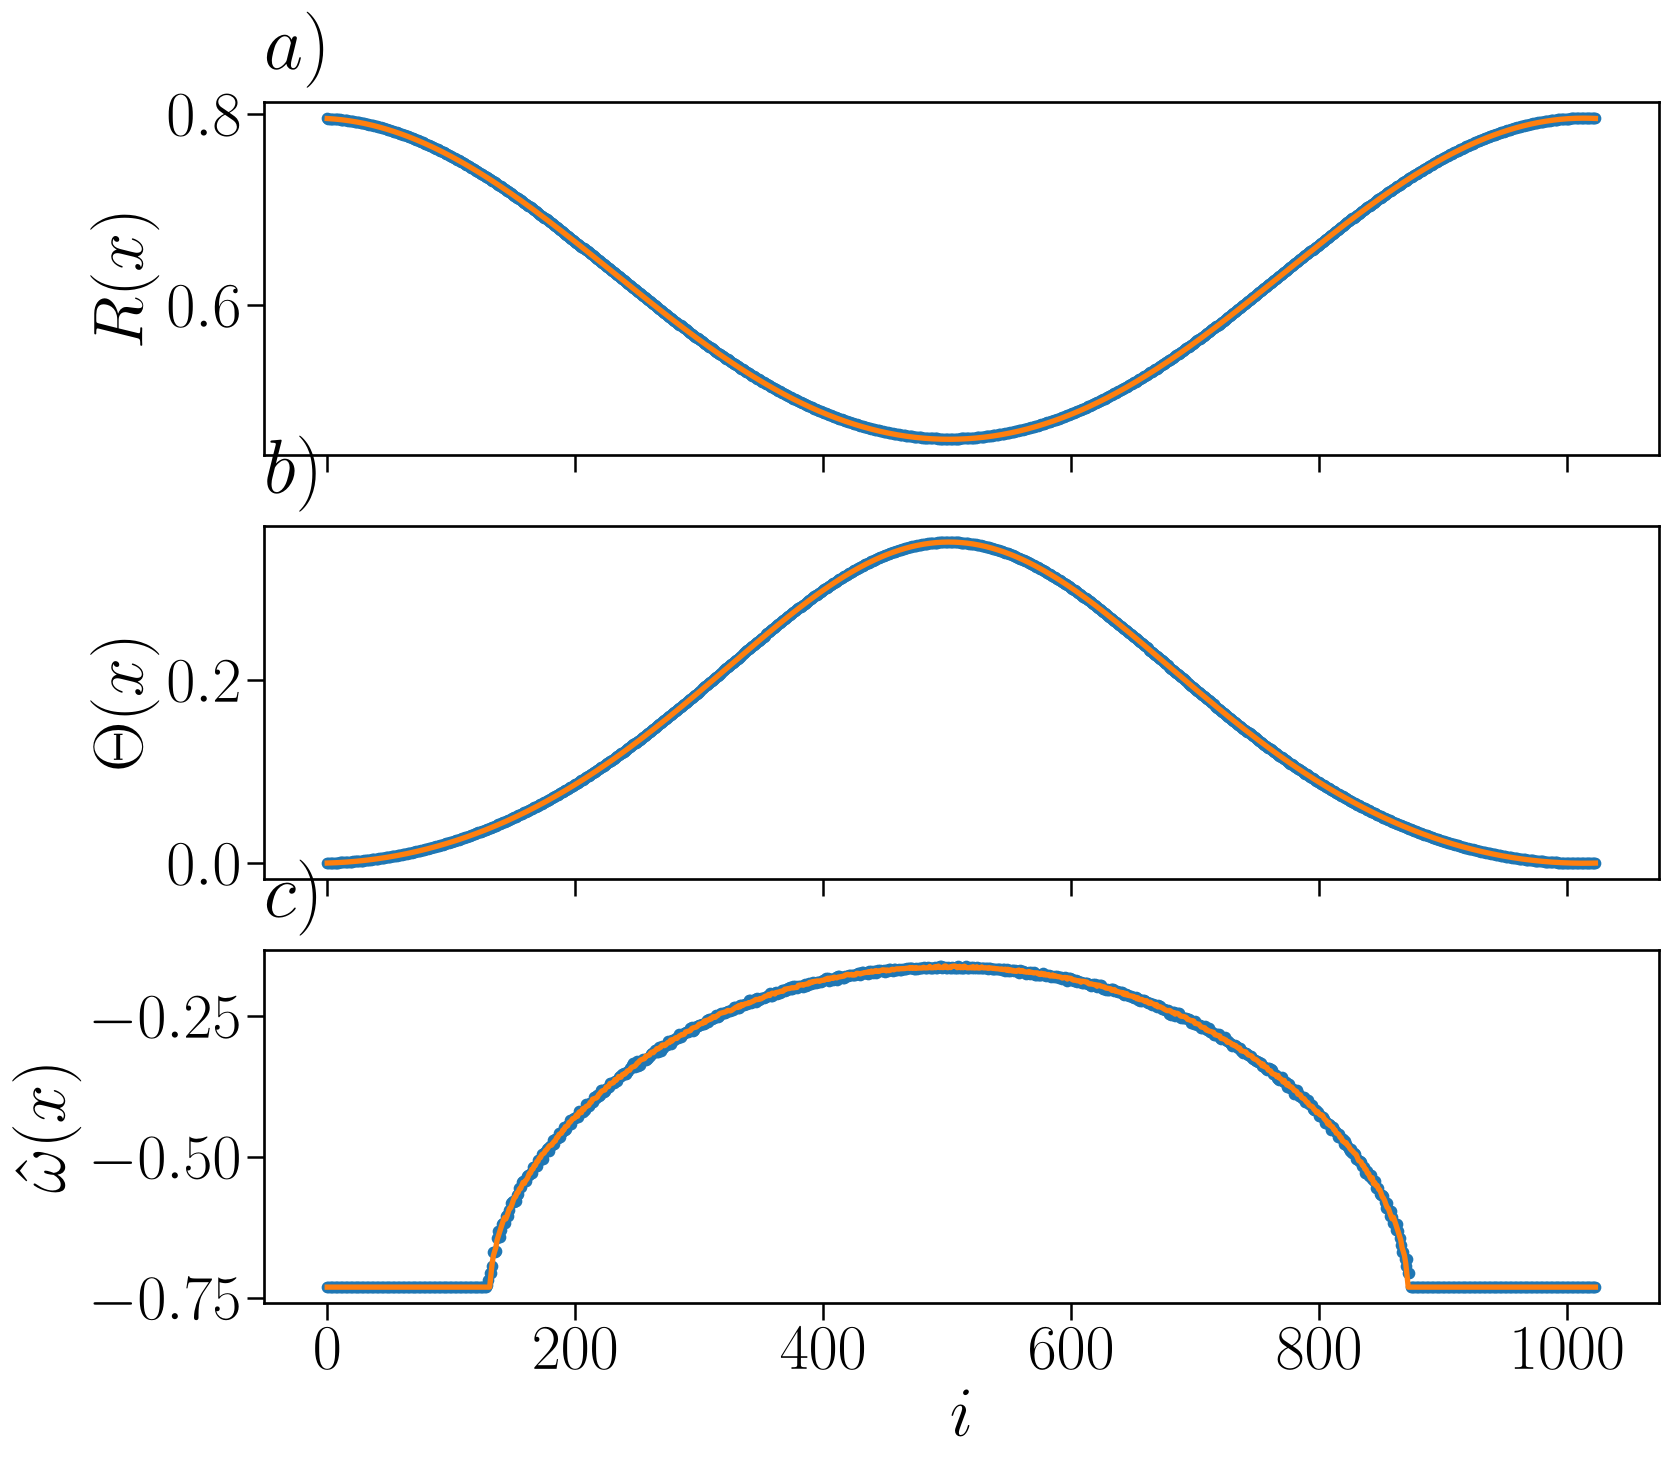

In [17]:
new_initial_conditions = init_state[-1] % (2 * np.pi)
model = vf_r_theta(omegas, Omega, r_sol, theta_sol, alpha)
dt = 0.1
sim_state = rk_interval(new_initial_conditions, model, 1000.0, dt)
sim_state = sim_state[1000:, :]

state_sim = np.unwrap(sim_state, axis=0)
omega_sim = (np.diff(state_sim, axis=0)).mean(axis=0) / dt

fig, ax = plt.subplots(3, sharex=True)
ax[0].scatter(np.arange(N), r_orig)
ax[0].plot(np.arange(N), r_sol, c="tab:orange")
ax[0].set_ylabel(r"$R(x)$")
ax[0].set_title(r"$a)$", loc="left")

ax[1].scatter(np.arange(N), theta_orig)
ax[1].plot(np.arange(N), theta_sol, c="tab:orange")
ax[1].set_ylabel(r"$\Theta(x)$")
ax[1].set_title(r"$b)$", loc="left")

ax[2].scatter(np.arange(N), omega_real)
ax[2].plot(np.arange(N), omega_sim + Omega, c="tab:orange")
ax[2].set_ylabel(r"$\hat{\omega}(x)$")
ax[2].set_xlabel(r"$i$")
ax[2].set_title(r"$c)$", loc="left")

plt.show()

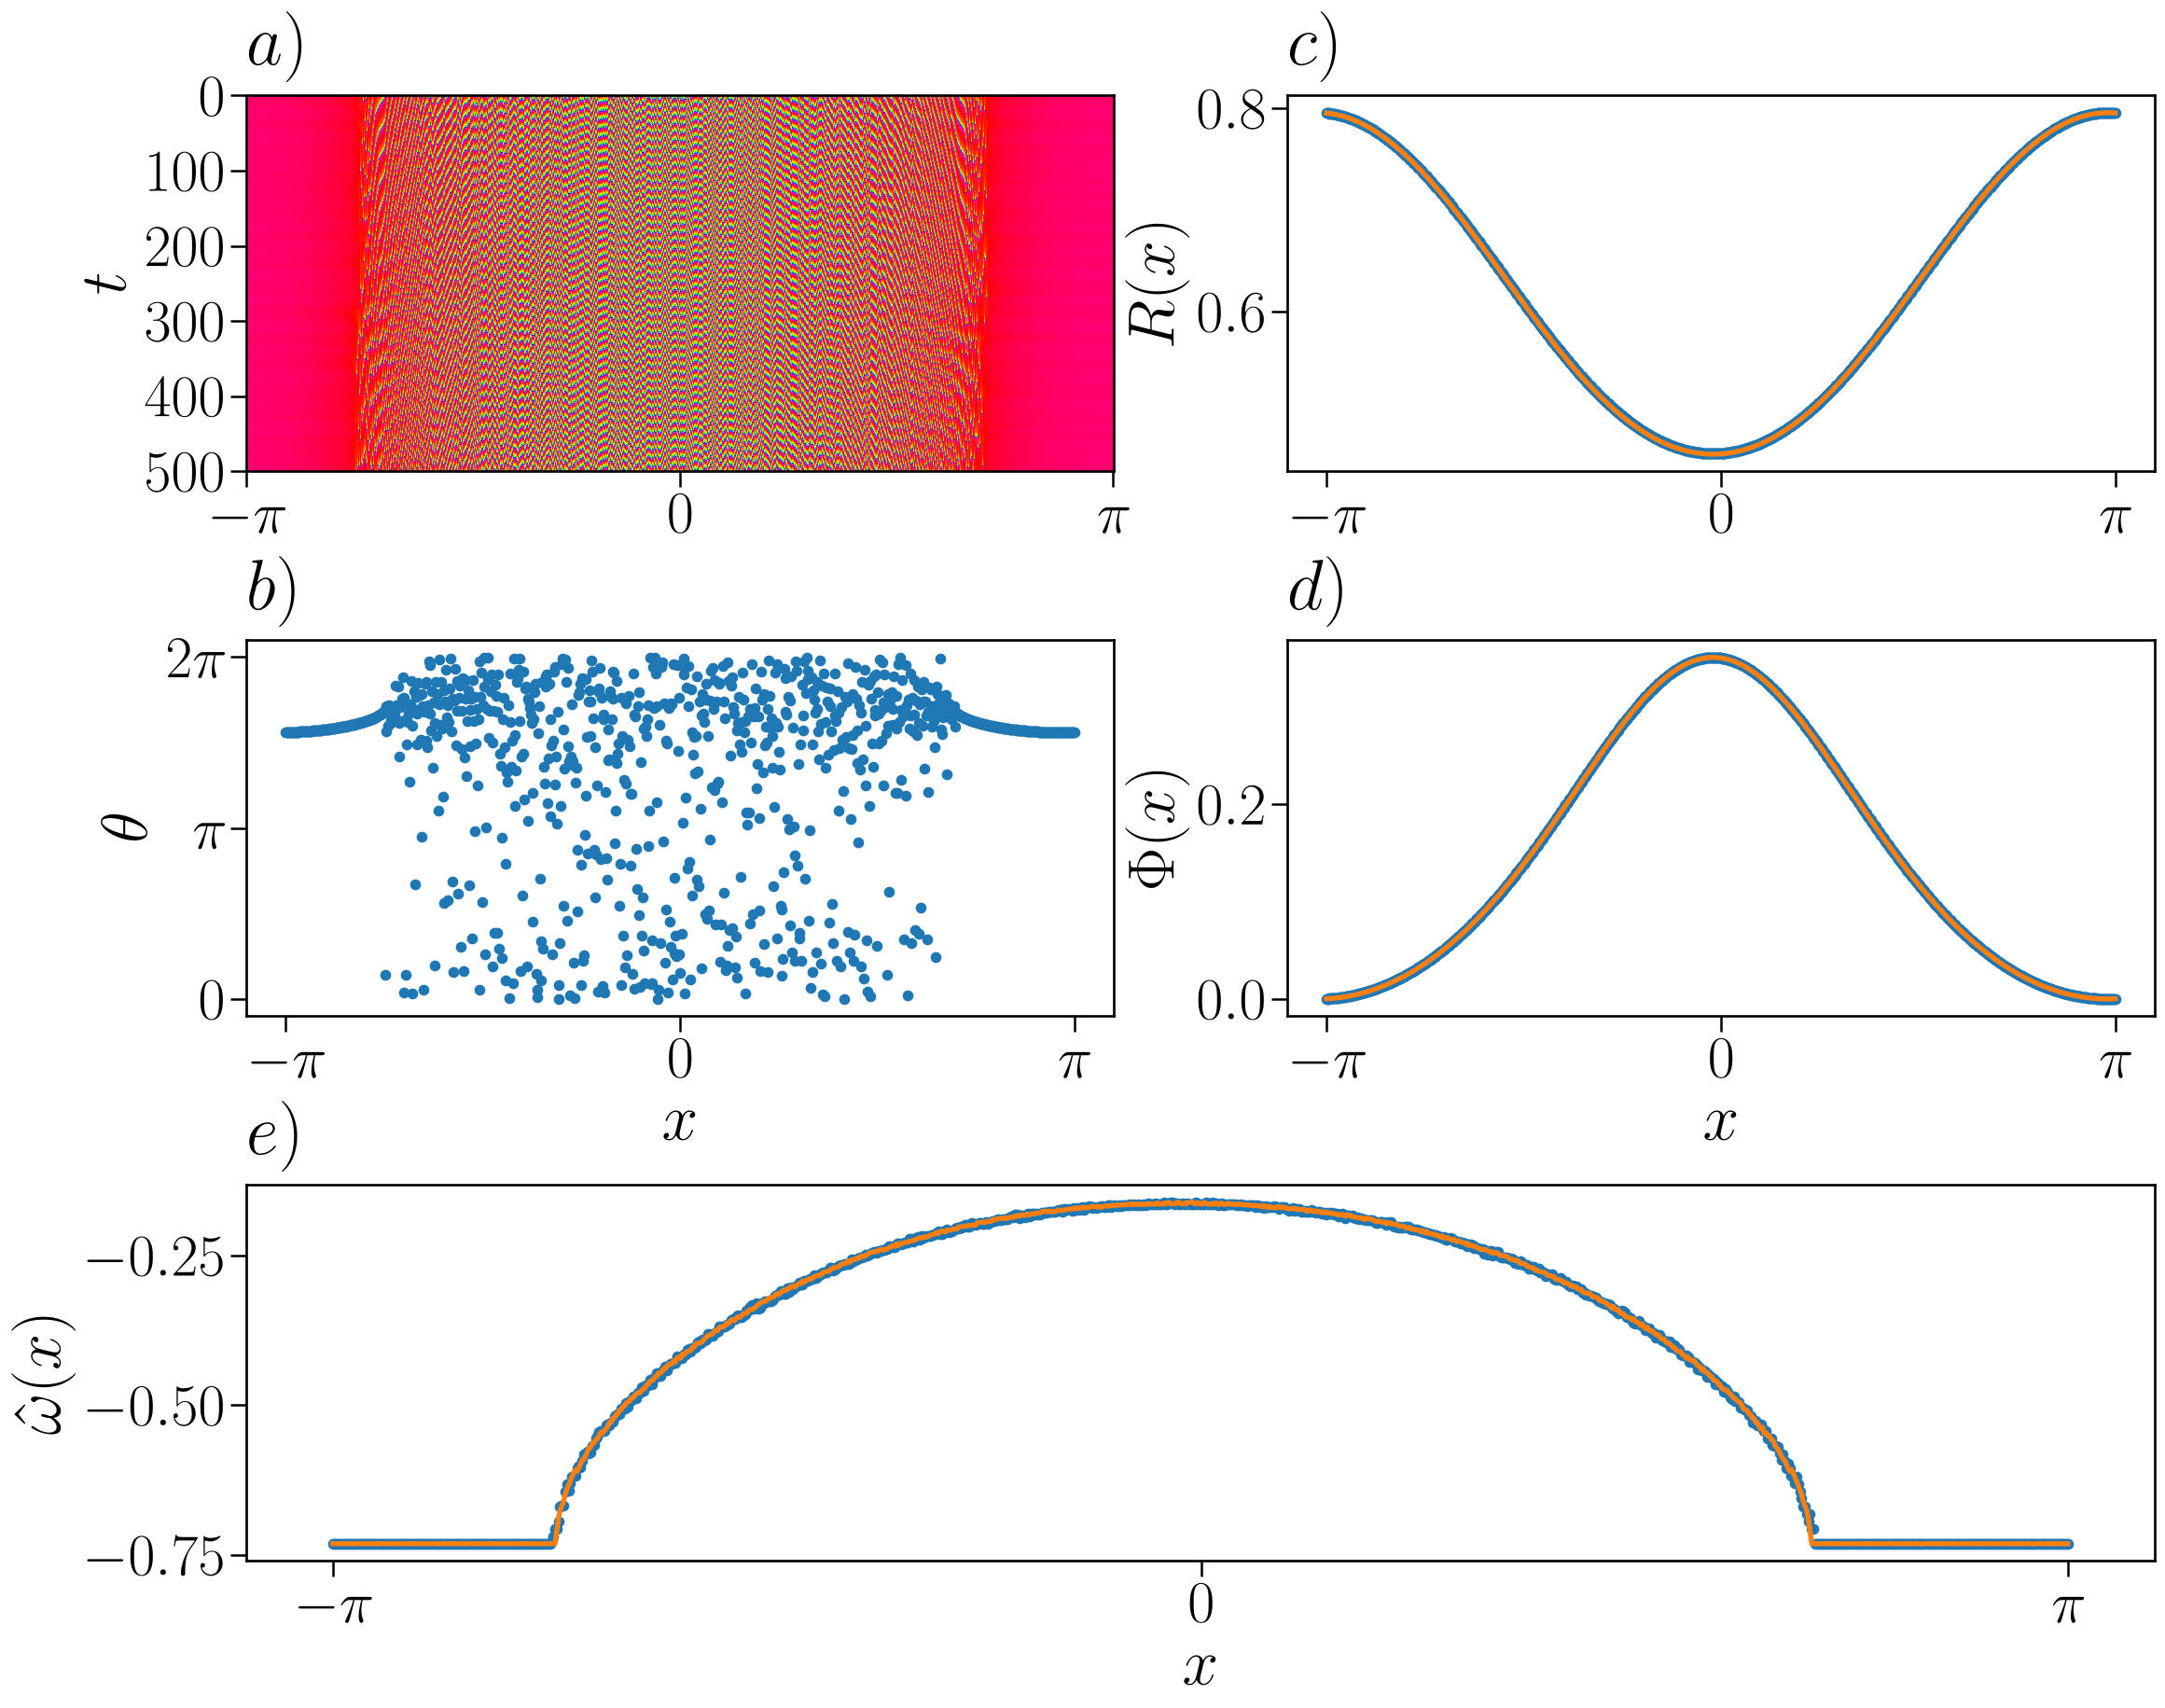

In [18]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(22, 17))
gs = GridSpec(3, 4, figure=fig)

ax1 = fig.add_subplot(gs[0, 0:2])

constant_phase = de_phase_solution(init_state)
ax1.imshow(
    constant_phase,
    aspect="auto",
    interpolation="none",
    cmap="hsv",
    vmin=0,
    vmax=2 * np.pi,
)
ax1.set_yticks(yticks)
ax1.set_yticklabels(ytick_labels)
ax1.set_ylabel(r"$t$")
ax1.set_title(r"$a)$", loc="left")
ax1.set_xticks([0, N / 2, N - 1])
ax1.set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])

ax2 = fig.add_subplot(gs[1, 0:2])
ax2.scatter(np.arange(N), init_state[5000] % (2 * np.pi))
ax2.set_yticks([0, np.pi, 2 * np.pi])
ax2.set_yticklabels([r"$0$", r"$\pi$", r"$2\pi$"])
ax2.set_xlabel(r"$x$")
ax2.set_ylabel(r"$\theta$")
ax2.set_title(r"$b)$", loc="left")
ax2.set_xticks([0, N / 2, N - 1])
ax2.set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])

ax3 = fig.add_subplot(gs[0, 2:])
ax3.scatter(np.arange(N), r_orig)
ax3.plot(np.arange(N), r_sol, c="tab:orange")
ax3.set_ylabel(r"$R(x)$")
ax3.set_title(r"$c)$", loc="left")
ax3.set_xticks([0, N / 2, N - 1])
ax3.set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])

ax4 = fig.add_subplot(gs[1, 2:])
ax4.scatter(np.arange(N), theta_orig)
ax4.plot(np.arange(N), theta_sol, c="tab:orange")
ax4.set_ylabel(r"$\Phi(x)$")
ax4.set_xlabel(r"$x$")
ax4.set_title(r"$d)$", loc="left")
ax4.set_xticks([0, N / 2, N - 1])
ax4.set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])

ax5 = fig.add_subplot(gs[2, :])
ax5.scatter(np.arange(N), omega_real)
ax5.plot(np.arange(N), omega_sim + Omega, c="tab:orange")
ax5.set_ylabel(r"$\hat{\omega}(x)$")
ax5.set_xlabel(r"$x$")
ax5.set_title(r"$e)$", loc="left")
ax5.set_xticks([0, N / 2, N - 1])
ax5.set_xticklabels([r"$-\pi$", r"$0$", r"$\pi$"])

plt.subplots_adjust(hspace=0.45, wspace=0.5, right=0.9)


plt.savefig(BASE_FOLDER / "1.pdf", bbox_inches="tight")
plt.show()